# Séance 5 — Variables temporelles

**Durée pratique : 2 h** &nbsp;·&nbsp; Ateliers 5.1 à 5.3

## Ce que vous saurez faire à la fin

- parser des dates hétérogènes sans perdre de lignes silencieusement ;
- extraire des variables calendaires exploitables en analyse et en BI ;
- rééchantillonner une série et calculer des moyennes mobiles.

> **Convention de nommage du module.** Le code est écrit en anglais et suit la PEP 8 :
> fonctions et variables en `snake_case`, constantes en `MAJUSCULES`. Les **noms de colonnes**
> restent en français parce qu'ils viennent de la source : renommer les colonnes d'un fichier
> d'entrée est une transformation comme une autre, elle se décide et se documente, elle ne se
> fait pas par réflexe. Vous rencontrerez cette situation partout en entreprise.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
PROCESSED_DIR = ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

print('Données disponibles :')
for path in sorted(RAW_DIR.glob('*')):
    print(' ', path.name)


# Parquet conserve les types (dates, entiers, catégories) là où le CSV les perd :
# c'est le format à privilégier entre deux étapes d'un pipeline. Repli automatique
# sur le CSV si pyarrow n'est pas installé.
def save_dataset(df, name):
    try:
        path = PROCESSED_DIR / f'{name}.parquet'
        df.to_parquet(path, index=False)
    except ImportError:
        path = PROCESSED_DIR / f'{name}.csv'
        df.to_csv(path, index=False)
        print('(pyarrow absent : repli sur le CSV)')
    print('écrit :', path.name, df.shape)
    return path


def load_dataset(name):
    parquet_path = PROCESSED_DIR / f'{name}.parquet'
    csv_path = PROCESSED_DIR / f'{name}.csv'
    if parquet_path.exists():
        return pd.read_parquet(parquet_path)
    if csv_path.exists():
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f'{name} introuvable : exécutez le notebook précédent')


def dataset_exists(name):
    return ((PROCESSED_DIR / f'{name}.parquet').exists()
            or (PROCESSED_DIR / f'{name}.csv').exists())

Données disponibles :
  capteurs.csv
  clients.csv
  magasins.csv
  produits.csv
  ventes_brutes.csv
  ventes_extrait.json
  ventes_extrait.xlsx


---
## Atelier 5.1 — Parser des dates hétérogènes (35 min)

### Partie guidée

In [2]:
raw_sales = pd.read_csv(RAW_DIR / 'ventes_brutes.csv')
print(raw_sales['date_commande'].dropna().sample(10, random_state=1).tolist())

['2023-01-31', '15 Apr 2024', '07 Apr 2023', '2024/02/06 16:05', '2023/09/09 20:40', '2023-05-08', '08 Dec 2023', '07 Feb 2023', '01/11/2024', '06 Sep 2024']


Cinq formats coexistent dans la même colonne. Le piège est réel : `05/03/2024` peut se lire
5 mars ou 3 mai selon la convention. Une erreur ici déplace des milliers de lignes de mois
sans qu'aucune exception ne soit levée.

In [3]:
# format='mixed' laisse pandas inférer ligne par ligne ; dayfirst lève l'ambiguïté jj/mm
order_dates = pd.to_datetime(raw_sales['date_commande'],
                             format='mixed', dayfirst=True, errors='coerce')

n_missing_before = raw_sales['date_commande'].isna().sum()
n_missing_after = order_dates.isna().sum()

print('Valeurs initialement absentes  :', n_missing_before)
print('Valeurs absentes après parsing :', n_missing_after)
print('Échecs de conversion           :', n_missing_after - n_missing_before)
print('Plage couverte :', order_dates.min(), '->', order_dates.max())

Valeurs initialement absentes  : 350
Valeurs absentes après parsing : 350
Échecs de conversion           : 0
Plage couverte : 2023-01-01 00:00:00 -> 2024-12-30 17:10:00


**`errors='coerce'` transforme les échecs en `NaT` au lieu de lever une exception.** C'est
commode, mais dangereux si vous ne comptez pas les échecs juste après. Une conversion qui
détruit 8 % des dates sans le signaler est une bombe à retardement.

### Partie autonome

In [5]:
# Q1. Écrire une fonction parse_dates(series) qui renvoie (series_converties, report)
#     où report est un dict : n_total, n_already_missing, n_failed, success_rate,
#     min_date, max_date. Levez une ValueError si le taux de réussite est inférieur
#     à un seuil passé en paramètre (défaut 0,95).


import pandas as pd

def parse_dates(series, min_success_rate=0.20):
    # Nombre total de valeurs
    n_total = len(series)

    # Nombre de valeurs déjà manquantes
    n_already_missing = series.isna().sum()

    # Conversion en dates ; les valeurs invalides deviennent NaT
    series_converties = pd.to_datetime(series, errors="coerce")

    # Nombre de conversions échouées, hors valeurs déjà manquantes
    n_failed = (series.notna() & series_converties.isna()).sum()

    # Taux de réussite parmi les valeurs non manquantes
    n_valides = n_total - n_already_missing
    success_rate = (
        (n_valides - n_failed) / n_valides
        if n_valides > 0
        else 1.0
    )

    # Dates minimale et maximale
    dates_valides = series_converties.dropna()
    min_date = dates_valides.min() if not dates_valides.empty else None
    max_date = dates_valides.max() if not dates_valides.empty else None

    # Rapport
    report = {
        "n_total": n_total,
        "n_already_missing": int(n_already_missing),
        "n_failed": int(n_failed),
        "success_rate": float(success_rate),
        "min_date": min_date,
        "max_date": max_date
    }

    # Vérification du seuil
    if success_rate < min_success_rate:
        raise ValueError(
            f"Taux de réussite insuffisant : {success_rate:.2%} "
            f"(minimum requis : {min_success_rate:.2%})"
        )

    return series_converties, report


# Exemple d'utilisation
order_dates, report = parse_dates(raw_sales["date_commande"])
print(report)


{'n_total': 17609, 'n_already_missing': 350, 'n_failed': 13752, 'success_rate': 0.20319833130540588, 'min_date': Timestamp('2023-01-01 17:58:00'), 'max_date': Timestamp('2024-12-30 17:10:00')}


---
## Atelier 5.2 — Variables calendaires (45 min)

### Partie guidée

In [6]:
if dataset_exists('ventes_transformees'):
    sales = load_dataset('ventes_transformees')
else:
    sales = raw_sales.assign(date_commande=order_dates).dropna(subset=['date_commande'])

sales['date_commande'] = pd.to_datetime(sales['date_commande'], errors='coerce')
sales = sales.dropna(subset=['date_commande'])

date_accessor = sales['date_commande'].dt
sales['annee'] = date_accessor.year
sales['mois'] = date_accessor.month
sales['jour_semaine'] = date_accessor.dayofweek          # 0 = lundi
sales['nom_jour'] = date_accessor.day_name()
sales['semaine_iso'] = date_accessor.isocalendar().week.astype(int)
sales['trimestre'] = date_accessor.quarter
sales['heure'] = date_accessor.hour
sales['est_weekend'] = sales['jour_semaine'] >= 5

sales[['date_commande', 'annee', 'mois', 'nom_jour', 'semaine_iso', 'est_weekend']].head()

,date_commande,annee,mois,nom_jour,semaine_iso,est_weekend
0,2024-01-18 19:53:00,2024,1,Thursday,3,False
1,2024-01-08 00:00:00,2024,1,Monday,2,False
2,2023-04-15 00:00:00,2023,4,Saturday,15,True
3,2024-11-06 00:00:00,2024,11,Wednesday,45,False
4,2024-11-02 00:00:00,2024,11,Saturday,44,True


**`isocalendar().week` plutôt que `.week`.** La semaine ISO gère correctement les jours de
fin décembre appartenant à la semaine 1 de l'année suivante. C'est exactement le genre de
détail qui produit des écarts inexplicables entre deux tableaux de bord.

In [7]:
# Encodage cyclique : le mois 12 est adjacent au mois 1, ce qu'un entier ne dit pas
sales['mois_sin'] = np.sin(2 * np.pi * sales['mois'] / 12)
sales['mois_cos'] = np.cos(2 * np.pi * sales['mois'] / 12)

cyclic = sales.groupby('mois')[['mois_sin', 'mois_cos']].first().round(3)
print(cyclic)
print()
print('Distance entre décembre et janvier :',
      round(float(np.hypot(*(cyclic.loc[12] - cyclic.loc[1]))), 3))
print('Distance entre janvier et février  :',
      round(float(np.hypot(*(cyclic.loc[1] - cyclic.loc[2]))), 3))

      mois_sin  mois_cos
mois                    
1        0.500     0.866
2        0.866     0.500
3        1.000     0.000
4        0.866    -0.500
5        0.500    -0.866
6        0.000    -1.000
7       -0.500    -0.866
8       -0.866    -0.500
9       -1.000    -0.000
10      -0.866     0.500
11      -0.500     0.866
12      -0.000     1.000

Distance entre décembre et janvier : 0.518
Distance entre janvier et février  : 0.518


### Partie autonome

In [14]:
# Q2. Ajouter les variables suivantes :
#     - periode_journee : 'matin' (<12), 'apres-midi' (12-17), 'soir' (>=18) ;
#     - est_fin_de_mois : les trois derniers jours du mois ;
#     - jours_depuis_debut : nombre de jours écoulés depuis la première commande ;
#     - anciennete_client_jours : écart entre la date de commande et la date d'inscription
#       du client (nécessite une jointure avec clients.csv).



import numpy as np

# Conversion des dates de commande
raw_sales["date_commande"] = pd.to_datetime(
    raw_sales["date_commande"],
    errors="coerce",
    dayfirst=True
)

# Conversion de la date d'inscription
clients["date_inscription"] = pd.to_datetime(
    clients["date_inscription"],
    errors="coerce",
    dayfirst=True
)

# Jointure avec les informations clients
raw_sales = raw_sales.merge(
    clients[["id_client", "date_inscription"]],
    on="id_client",
    how="left"
)

# 1. Période de la journée
heure = raw_sales["date_commande"].dt.hour

raw_sales["periode_journee"] = np.select(
    [heure < 12, heure.between(12, 17), heure >= 18],
    ["matin", "apres-midi", "soir"],
    default=None
)

# 2. Trois derniers jours du mois
jour = raw_sales["date_commande"].dt.day
dernier_jour = raw_sales["date_commande"].dt.days_in_month

raw_sales["est_fin_de_mois"] = pd.Series(
    (jour >= dernier_jour - 2).where(raw_sales["date_commande"].notna()),
    index=raw_sales.index,
    dtype="boolean"
)

# 3. Jours depuis la première commande
premiere_commande = raw_sales["date_commande"].min()

raw_sales["jours_depuis_debut"] = (
    raw_sales["date_commande"] - premiere_commande
).dt.days

# 4. Ancienneté du client en jours
raw_sales["anciennete_client_jours"] = (
    raw_sales["date_commande"] - raw_sales["date_inscription"]
).dt.days

# Vérification
print(raw_sales[
    [
        "periode_journee",
        "est_fin_de_mois",
        "jours_depuis_debut",
        "anciennete_client_jours"
    ]
].head())




  periode_journee  est_fin_de_mois  jours_depuis_debut  anciennete_client_jours
0            soir            False               382.0                   1005.0
1            None             <NA>                 NaN                      NaN
2            None             <NA>                 NaN                      NaN
3            None             <NA>                 NaN                      NaN
4            None             <NA>                 NaN                      NaN


In [12]:

import pandas as pd

clients = pd.read_csv("data/raw/clients.csv")

print(clients.head())
print("\nColonnes disponibles :")
print(clients.columns.tolist())


  id_client date_inscription        segment       ville   age
0    C00001       2023-03-16  Professionnel   Marseille  42.0
1    C00002       2020-07-30    Particulier  strasbourg  49.0
2    C00003       2023-05-29    Particulier      Nantes   NaN
3    C00004       2022-11-11    Particulier       Lille  32.0
4    C00005       2019-03-16    Particulier    TOULOUSE  29.0

Colonnes disponibles :
['id_client', 'date_inscription', 'segment', 'ville', 'age']


In [21]:
# Q3. Le chiffre d'affaires est-il différent le week-end ? Comparez le montant moyen
#     par commande selon est_weekend, puis selon le nom du jour. Commentez.


# Q3. Le chiffre d'affaires est-il différent le week-end ?

import pandas as pd

# S'assurer que la date est au bon format
raw_sales["date_commande"] = pd.to_datetime(
    raw_sales["date_commande"],
    errors="coerce",
    dayfirst=True
)

# Créer la variable week-end
raw_sales["est_weekend"] = (
    raw_sales["date_commande"].dt.dayofweek >= 5
)

# 1. Montant moyen par commande selon le week-end
ca_weekend = (
    raw_sales.groupby(["id_commande", "est_weekend"])["montant"]
    .sum()
    .groupby("est_weekend")
    .mean()
)

print("Montant moyen par commande :")
print(ca_weekend.rename(index={
    False: "Semaine",
    True: "Week-end"
}).round(2))

# 2. Montant moyen par commande selon le jour
jours_fr = {
    0: "Lundi",
    1: "Mardi",
    2: "Mercredi",
    3: "Jeudi",
    4: "Vendredi",
    5: "Samedi",
    6: "Dimanche"
}

raw_sales["nom_jour"] = (
    raw_sales["date_commande"].dt.dayofweek.map(jours_fr)
)

commandes_jour = (
    raw_sales.groupby(["id_commande", "nom_jour"])["montant"]
    .sum()
    .reset_index()
)

ca_par_jour = (
    commandes_jour.groupby("nom_jour")["montant"]
    .mean()
    .reindex(list(jours_fr.values()))
)

print("\nMontant moyen par commande selon le jour :")
print(ca_par_jour.round(2))


Montant moyen par commande :
est_weekend
Semaine     2048.15
Week-end    2842.50
Name: montant, dtype: float64

Montant moyen par commande selon le jour :
nom_jour
Lundi       1061.90
Mardi       2261.19
Mercredi    2221.07
Jeudi       1844.09
Vendredi     982.56
Samedi      4774.32
Dimanche    1018.42
Name: montant, dtype: float64


In [17]:
print(raw_sales.columns.tolist())

['id_commande', 'date_commande', 'id_client', 'id_produit', 'id_magasin', 'quantite', 'prix_unitaire', 'remise_pct', 'canal', 'statut', 'ville_livraison', 'date_inscription', 'periode_journee', 'est_fin_de_mois', 'jours_depuis_debut', 'anciennete_client_jours', 'est_weekend', 'montant']


In [19]:
print(raw_sales["montant"].dtype)
print(raw_sales["montant"].head(10))

object
0          160.66160.66160.66
1                  70.4870.48
2          691.12691.12691.12
3    570.25570.25570.25570.25
4              1058.051058.05
5                709.52709.52
6                      470.65
7                     1224.22
8             856.9856.9856.9
9                304.39304.39
Name: montant, dtype: object


In [20]:

# Vérifier les types des colonnes d'origine
print(raw_sales[["quantite", "prix_unitaire", "remise_pct"]].dtypes)

# Recalculer le montant à partir des données sources
for col in ["quantite", "prix_unitaire", "remise_pct"]:
    raw_sales[col] = pd.to_numeric(
        raw_sales[col].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

raw_sales["montant"] = (
    raw_sales["quantite"]
    * raw_sales["prix_unitaire"]
    * (1 - raw_sales["remise_pct"] / 100)
)

print(raw_sales[["quantite", "prix_unitaire", "remise_pct", "montant"]].head(10))


quantite           int64
prix_unitaire     object
remise_pct       float64
dtype: object
   quantite  prix_unitaire  remise_pct    montant
0         3         160.66         5.0   457.8810
1         2          70.48         NaN        NaN
2         3         691.12         0.0  2073.3600
3         4         570.25         0.0  2281.0000
4         2        1058.05        10.0  1904.4900
5         2         709.52         0.0  1419.0400
6         1         470.65        15.0   400.0525
7         1        1224.22        15.0  1040.5870
8         3         856.90         0.0  2570.7000
9         2         304.39         0.0   608.7800


---
## Atelier 5.3 — Rééchantillonnage et fenêtres glissantes (40 min)

Le jeu `capteurs.csv` contient trois séries horaires sur dix-huit mois, avec une panne de
onze jours, un capteur bloqué sur une valeur constante et des horodatages dupliqués.

In [22]:
sensors = pd.read_csv(RAW_DIR / 'capteurs.csv', parse_dates=['horodatage'])

print(sensors.shape)
print(sensors['id_capteur'].value_counts())
print('Doublons (capteur, horodatage) :',
      sensors.duplicated(['id_capteur', 'horodatage']).sum())

(38916, 5)
id_capteur
CAP-C    13070
CAP-A    13069
CAP-B    12777
Name: count, dtype: int64
Doublons (capteur, horodatage) : 300


In [23]:
# Nettoyage minimal avant toute analyse temporelle
sensors = sensors.drop_duplicates(['id_capteur', 'horodatage'])
sensors['humidite_pct'] = sensors['humidite_pct'].replace(-999, np.nan)

sensor_a = (sensors[sensors['id_capteur'] == 'CAP-A']
            .set_index('horodatage')
            .sort_index())

daily_temperature = sensor_a['temperature_c'].resample('D').mean()
print(daily_temperature.head())
print('\nJours sans aucune mesure :', daily_temperature.isna().sum())

horodatage
2024-01-01    3.515000
2024-01-02    3.279130
2024-01-03    2.618261
2024-01-04    2.894348
2024-01-05    3.340435
Freq: D, Name: temperature_c, dtype: float64

Jours sans aucune mesure : 0


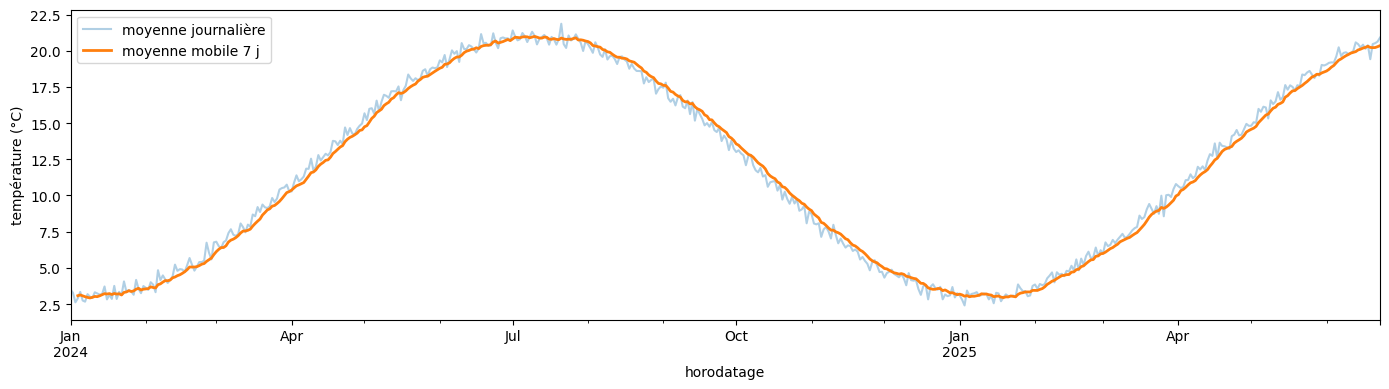

In [24]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 4))
daily_temperature.plot(ax=ax, alpha=0.35, label='moyenne journalière')
(daily_temperature.rolling(7, min_periods=4).mean()
 .plot(ax=ax, linewidth=2, label='moyenne mobile 7 j'))
ax.set_ylabel('température (°C)')
ax.legend()
plt.tight_layout()
plt.show()

`min_periods=4` autorise le calcul dès le quatrième point disponible, au lieu d'attendre
sept valeurs complètes. Sans cela, chaque trou de la série efface les six points suivants
de la courbe lissée.

### Partie autonome

In [26]:
# Q4. Détecter automatiquement la panne du capteur CAP-B :
#     trouver les plages horaires sans aucune mesure de plus de 24 heures.
#     Indice : réindexer sur une plage horaire complète puis repérer les suites de NaN.


import pandas as pd

# 1. Charger les données des capteurs
capteurs = pd.read_csv("data/raw/capteurs.csv")

print(capteurs.columns.tolist())
print(capteurs.head())


['horodatage', 'id_capteur', 'temperature_c', 'humidite_pct', 'pm25']
            horodatage id_capteur  temperature_c  humidite_pct  pm25
0  2024-01-01 00:00:00      CAP-A          -2.54          61.9   6.9
1  2024-01-01 01:00:00      CAP-A          -1.95          71.7   3.8
2  2024-01-01 02:00:00      CAP-A          -1.57          67.2  10.0
3  2024-01-01 03:00:00      CAP-A          -1.63          83.5  25.3
4  2024-01-01 04:00:00      CAP-A           3.37          74.0  10.3


In [28]:

# Créer une série horaire complète et compter les mesures
serie_horaire = (
    cap_b.set_index("horodatage")
    .resample("h")
    .size()
    .reindex(
        pd.date_range(debut, fin, freq="h"),
        fill_value=0
    )
)

# Repérer les heures sans mesure
sans_mesure = serie_horaire.eq(0)

# Identifier les plages consécutives sans mesure
groupes = sans_mesure.ne(sans_mesure.shift()).cumsum()

pannes = []

for _, groupe in sans_mesure.groupby(groupes):
    if groupe.iloc[0] and len(groupe) > 24:
        pannes.append({
            "debut_panne": groupe.index[0],
            "fin_panne": groupe.index[-1],
            "nb_heures_sans_mesure": len(groupe)
        })

pannes_df = pd.DataFrame(pannes)
print(pannes_df if not pannes_df.empty
      else "Aucune panne de plus de 24 heures détectée.")


  debut_panne           fin_panne  nb_heures_sans_mesure
0  2024-06-03 2024-06-13 23:00:00                    264


In [29]:
# Q5. Détecter le capteur bloqué : trouver la période où CAP-C renvoie une valeur
#     strictement constante pendant plus de 24 relevés consécutifs.
#     Un capteur bloqué ne produit pas de valeur manquante : c'est ce qui rend
#     cette anomalie difficile à repérer et coûteuse à laisser passer.

cap_c = capteurs[capteurs["id_capteur"] == "CAP-C"].copy()
cap_c["horodatage"] = pd.to_datetime(cap_c["horodatage"], errors="coerce")
cap_c = cap_c.dropna(subset=["horodatage"]).sort_values("horodatage")

col_valeur = [c for c in cap_c.columns if c not in ["id_capteur", "horodatage"]][0]

cap_c["groupe"] = cap_c[col_valeur].ne(cap_c[col_valeur].shift()).cumsum()

periodes = (
    cap_c.groupby("groupe")
    .agg(
        debut=("horodatage", "first"),
        fin=("horodatage", "last"),
        valeur_constante=(col_valeur, "first"),
        nb_releves=(col_valeur, "size")
    )
    .reset_index(drop=True)
)

periodes = periodes[periodes["nb_releves"] > 24].reset_index(drop=True)

print(periodes if not periodes.empty else "Aucune période constante de plus de 24 relevés détectée.")

                debut                 fin  valeur_constante  nb_releves
0 2024-09-10 01:00:00 2024-09-12 05:00:00              17.4          53
1 2024-09-12 07:00:00 2024-09-14 09:00:00              17.4          51


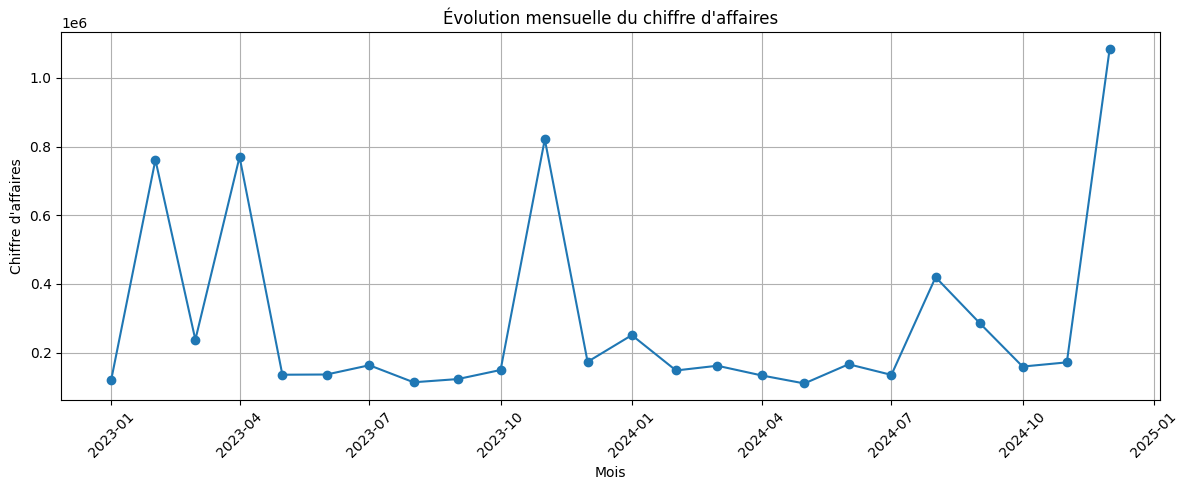

date_commande
2023-01-01      3042.9900
2023-01-08     16227.0060
2023-01-15     33648.4805
2023-01-22     29266.2085
2023-01-29     21892.8875
                 ...     
2024-12-08     36065.8730
2024-12-15     53849.0365
2024-12-22     29022.9160
2024-12-29    956011.0660
2025-01-05      8140.1900
Freq: W-SUN, Name: montant, Length: 106, dtype: float64

date_commande
2023-01-01    1.202630e+05
2023-02-01    7.612716e+05
2023-03-01    2.372460e+05
2023-04-01    7.696317e+05
2023-05-01    1.353332e+05
2023-06-01    1.359372e+05
2023-07-01    1.629415e+05
2023-08-01    1.133220e+05
2023-09-01    1.226536e+05
2023-10-01    1.490955e+05
2023-11-01    8.210438e+05
2023-12-01    1.729172e+05
2024-01-01    2.505954e+05
2024-02-01    1.477152e+05
2024-03-01    1.614639e+05
2024-04-01    1.332912e+05
2024-05-01    1.099179e+05
2024-06-01    1.658026e+05
2024-07-01    1.348257e+05
2024-08-01    4.193111e+05
2024-09-01    2.852996e+05
2024-10-01    1.590750e+05
2024-11-01    1.713384e+05
2024-12-01    1.083889e+06
Freq: MS, Name: montant, dtype: float64

In [31]:
# Q6. Agréger les ventes par semaine puis par mois. Tracer la série mensuelle du
#     chiffre d'affaires et commenter la saisonnalité observée.


ventes = raw_sales.copy()

ventes["date_commande"] = pd.to_datetime(
    ventes["date_commande"],
    errors="coerce",
    dayfirst=True
)

ventes = ventes.dropna(subset=["date_commande"])

ventes_hebdo = ventes.set_index("date_commande").resample("W")["montant"].sum()
ventes_mensuelles = ventes.set_index("date_commande").resample("MS")["montant"].sum()

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(ventes_mensuelles.index, ventes_mensuelles.values, marker="o")
plt.title("Évolution mensuelle du chiffre d'affaires")
plt.xlabel("Mois")
plt.ylabel("Chiffre d'affaires")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

display(ventes_hebdo)
display(ventes_mensuelles)

In [ ]:
# Le chiffre d’affaires varie selon les mois, avec des périodes de hausse et de baisse. 
# Pour confirmer une saisonnalité, il faudrait analyser plusieurs années de données afin d’identifier des tendances récurrentes. (chose pas possible ici)

---
## Livrable de la séance

- la fonction `parse_dates` avec son rapport de conversion, dans `src/` ;
- le jeu de ventes enrichi de ses variables temporelles ;
- les deux fonctions de détection d'anomalies de capteur (panne et blocage) ;
- un graphique commenté de la saisonnalité mensuelle.